# Penjelasan Dataset yang digunakan

## 1. Kasus yang diambil

Dataset ini berisi kumpulan artikel berita dari CNN yang mencakup berbagai isu global seperti ekonomi, politik, kesehatan, kebijakan pemerintah, hingga dinamika krisis internasional yang terjadi selama periode pandemi Covid-19. Setiap artikel memuat judul, isi berita, tanggal publikasi, dan tautan sumber yang menunjukkan konteks asli berita tersebut. Berita-berita dalam dataset ini ditulis pada masa ketika pandemi memberikan dampak besar terhadap berbagai sektor, sehingga kontennya banyak membahas mengenai perubahan ekonomi global, respons negara terhadap krisis kesehatan, pelemahan pasar finansial, kebijakan perjalanan internasional, hingga strategi pemulihan ekonomi. Dengan cakupan topik yang luas dan bersifat real time terhadap kejadian global, dataset ini sangat relevan untuk dieksplorasi menggunakan teknik pemodelan topik. Melalui analisis ini, kita dapat mengidentifikasi tema-tema utama yang muncul dalam pemberitaan CNN dan memahami bagaimana isu-isu tersebut saling berkaitan serta berkembang sepanjang periode tersebut.

## 2. Penjelasan setiap kolom dataset
Dataset ini terdiri dari empat kolom utama, yaitu url, title, body, dan date.
1. Kolom url menyimpan alamat lengkap dari artikel CNN yang menjadi sumber berita, sehingga dapat digunakan sebagai identitas atau referensi asal artikel. Kolom ini akan dihapus dikarenakan kolom ini tidak diperlukan.
2. Kolom title berisi judul berita yang umumnya mencerminkan inti atau ringkasan dari topik yang dibahas.
3. Kolom body merupakan isi artikel secara keseluruhan yang memuat informasi lengkap dan detail mengenai peristiwa yang dilaporkan
4. kolom date mencatat tanggal publikasi artikel sehingga memungkinkan analisis berdasarkan waktu, seperti melihat perubahan tema berita dalam periode tertentu. Kolom ini akan dihapus dikarenakan kolom ini tidak diperlukan.


In [11]:
# Packages to store and manipulate data
import pandas as pd
import numpy as np

# Text Cleaning & NLP
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer
from nltk.tokenize import word_tokenize
from collections import Counter
from tqdm import tqdm
import string

# Download NLTK resources
nltk.download('punkt')
nltk.download('punkt_tab', quiet=True)
nltk.download('wordnet')
nltk.download('stopwords')

# Feature Extraction (Vectorization)
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Modeling (Topic Modeling, Dimensionality Reduction)
from sklearn.decomposition import LatentDirichletAllocation, PCA
from sklearn.manifold import TSNE

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Misc / Utilities
import sklearn


[nltk_data] Downloading package punkt to C:\Users\Java
[nltk_data]     Computer\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to C:\Users\Java
[nltk_data]     Computer\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to C:\Users\Java
[nltk_data]     Computer\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [2]:
df = pd.read_csv('CnnData.csv')

In [3]:
df

,url,title,body,date
0,https://www.cnn.com/2020/03/23/media/japan-abe...,Japan asked the international media to change ...,"In the new system ""Canton becomes Guangzhou an...",3/24/2020
1,https://www.cnn.com/2020/03/16/perspectives/us...,The United States is still too reliant on oil,Saudi Arabia's decision to open its taps comes...,3/24/2020
2,https://www.cnn.com/2020/03/23/investing/globa...,Global stocks and US futures rise as policymak...,The promise of unlimited support for markets f...,3/24/2020
3,https://www.cnn.com/2020/03/24/economy/china-e...,China is trying to revive its economy without ...,The country where the pandemic began was almos...,3/24/2020
4,https://www.cnn.com/2020/03/24/business/bailou...,Companies that binged on buybacks now seek bai...,"Now, some of the same companies that binged on...",3/24/2020
...,...,...,...,...
296,https://www.cnn.com/2020/03/31/business/food-s...,What happens to our food supply if American fa...,The coronavirus pandemic is posing a threat to...,4/1/2020
297,https://www.cnn.com/2019/07/31/tech/bill-nye-l...,Bill Nye's experimental spacecraft that sails ...,The prototype spacecraft is the work of the Pl...,3/24/2020
298,https://www.cnn.com/2020/03/26/perspectives/st...,These taxpayers won't get stimulus checks. Tha...,"Unfortunately, the Senate proposal does not in...",3/26/2020
299,https://www.cnn.com/2020/03/24/business/ford-3...,Ford is working with 3M and GE to make respira...,Healthcare workers around the country have exp...,3/24/2020


# Data Understanding

In [4]:
print("1. Jumlah baris dan kolom:", df.shape)

1. Jumlah baris dan kolom: (301, 4)


In [5]:
duplicates = df.duplicated().sum()
print("3. DATA DUPLIKAT")
print("Jumlah data duplikat (Baris persis sama):", duplicates)

if duplicates > 0:
    print("> Catatan: Pertimbangkan untuk menghapus duplikat: df = df.drop_duplicates()")
else:
    print("Tidak ada duplikasi baris.")

3. DATA DUPLIKAT
Jumlah data duplikat (Baris persis sama): 0
Tidak ada duplikasi baris.


In [6]:
missing = df.isnull().sum()
print("4. DATA KOSONG (Missing Values)")
print("Jumlah data kosong tiap kolom:", missing)

4. DATA KOSONG (Missing Values)
Jumlah data kosong tiap kolom: url      0
title    0
body     0
date     0
dtype: int64


In [7]:
if 'body' in df.columns:
    all_titles = " ".join(df['body'].astype(str).str.lower())
    words = all_titles.split()
    word_counts = Counter(words)
    df_top_words = (
        pd.DataFrame(word_counts.items(), columns=['Kata', 'Frekuensi'])
        .sort_values(by='Frekuensi', ascending=False)
        .head(10)
    )
    print(df_top_words)
else:
    print("Kolom 'title' tidak ditemukan.")

     Kata  Frekuensi
1     the      10952
16     to       7286
7     and       5372
70     of       4833
25      a       4408
0      in       3934
42   that       2678
29    for       2526
140    is       2095
231   are       1763


BAR CHART (10 Kata Kunci Teratas di Judul)


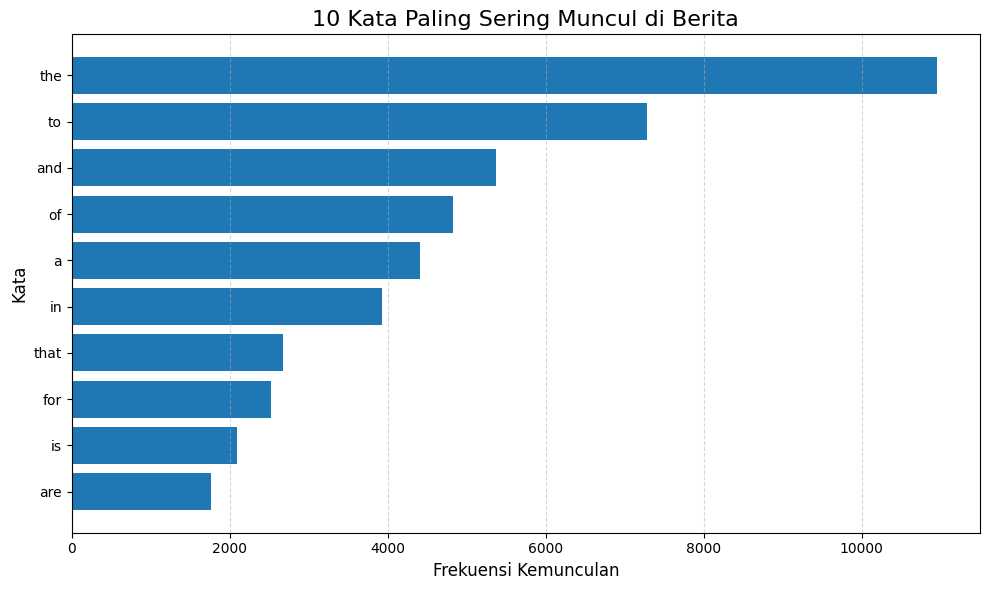

In [8]:
print("BAR CHART (10 Kata Kunci Teratas di Judul)")

if 'body' in df.columns:
    plt.figure(figsize=(10, 6))

    plt.barh(df_top_words['Kata'], df_top_words['Frekuensi'])
    plt.title('10 Kata Paling Sering Muncul di Berita', fontsize=16)
    plt.xlabel('Frekuensi Kemunculan', fontsize=12)
    plt.ylabel('Kata', fontsize=12)
    plt.grid(axis='x', linestyle='--', alpha=0.5)

    plt.gca().invert_yaxis()  # biar ranking 1 paling atas
    plt.tight_layout()
    plt.show()

else:
    print("Kolom 'title' tidak ditemukan. Bar Chart Frekuensi Kata tidak dapat dibuat.")

WORD CLOUD (Distribusi Kata di Body)


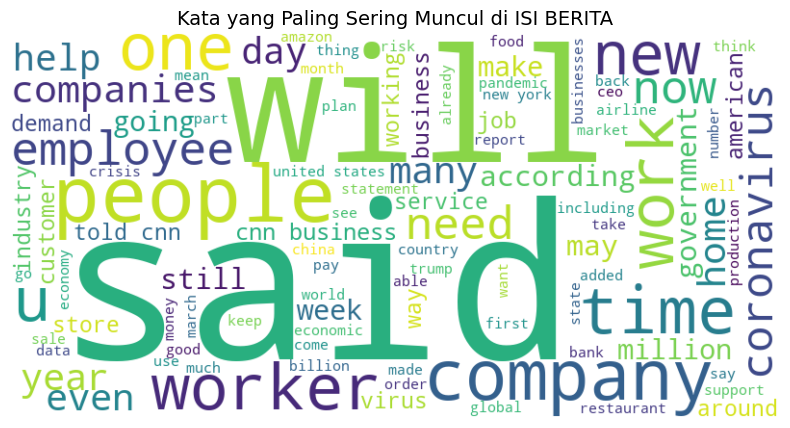

In [9]:
print("WORD CLOUD (Distribusi Kata di Body)")
if 'body' in df.columns:
    text_data_isi = " ".join(df['body'].astype(str).str.lower())

    wordcloud_isi = WordCloud(
        width=800,
        height=400,
        background_color='white',
        stopwords=None,
        max_words=100
    ).generate(text_data_isi)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud_isi, interpolation='bilinear')
    plt.axis("off")
    plt.title("Kata yang Paling Sering Muncul di ISI BERITA", fontsize=14)
    plt.show()

else:
    print("Kolom 'body' tidak ditemukan. Word Cloud tidak dapat dibuat.")

# Data Text Processing

In [28]:
default_stopwords = set(stopwords.words('english'))
custom_words = {'the', 'to', 'and', 'of', 'a', 'in', 'that', 'for', 'is', 'are', 'said', 'will', 'went', 'use', 'make','people', 'new', 'time', 'week', 'year', 'billion', 'million', 
    'cnn', 'like', 'told', 'according', 'march', 'going', 'working', 'day', 'weeks', 'years', 'including', 'dont',  'data', 'news', 'small', 'global', 'world', 
    'home', 'work' 'need', 'help', 'united','statement', 'announced', 'friday', 'support', 'service', 'services', 'need', 'pay'}
all_stopwords = default_stopwords.union(custom_words)

def preprocess_text(text):
    if not isinstance(text, str):
        return ""
        
    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'\d+', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\s+', ' ', text).strip()

    tokens = word_tokenize(text)
    filtered_tokens = [word for word in tokens if word not in all_stopwords and len(word) > 2]

    return " ".join(filtered_tokens)

tqdm.pandas()
df['text_clean'] = df['body'].astype(str).progress_apply(preprocess_text)

100%|██████████| 301/301 [00:00<00:00, 303.77it/s]


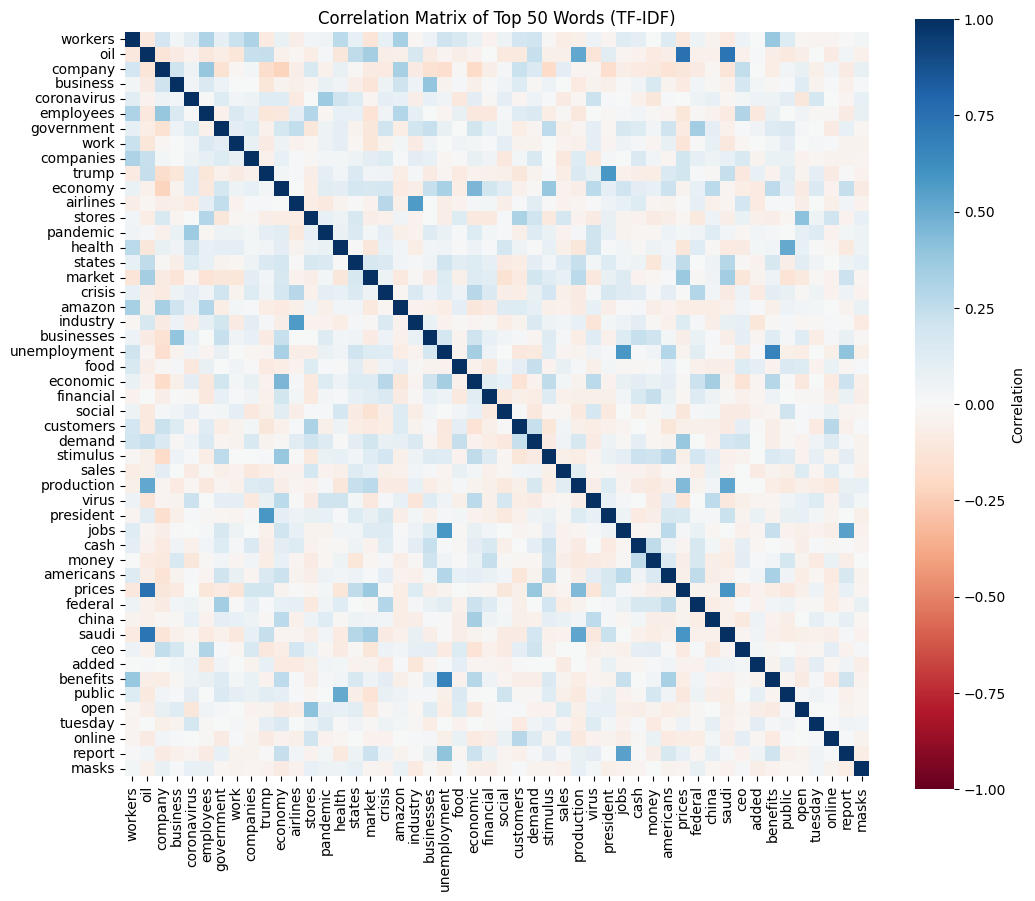

In [29]:
## Matrik korelasi

tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(df['text_clean'])

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out()
)
top_n = 50
top_words = tfidf_df.mean().sort_values(ascending=False).head(top_n).index
tfidf_top = tfidf_df[top_words]
correlation_matrix = tfidf_top.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    correlation_matrix,
    cmap='RdBu',
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={'label': 'Correlation'}
)
plt.title(f"Correlation Matrix of Top {top_n} Words (TF-IDF)")
plt.show()


In [30]:
## Teks vektorisasi

### TF-IDF Vectorizer
print("Menjalankan TF-IDF Vectorizer...")
vectorizer = TfidfVectorizer(stop_words='english')
X_tfidf = vectorizer.fit_transform(df['text_clean'])
low_idf_tokens = [
    word for word, idf in zip(vectorizer.get_feature_names_out(), vectorizer.idf_)
    if idf < 1.5
]
print(f"Jumlah token dengan IDF < 1.5: {len(low_idf_tokens)}")
print(f"Contoh token umum: {low_idf_tokens[:10]}")


### Count Vectorizer
print("\nMenjalankan Count Vectorizer...")
count_vectorizer = CountVectorizer(stop_words='english')
X_count = count_vectorizer.fit_transform(df['text_clean'])
count_df = pd.DataFrame(
    X_count.toarray(),
    columns=count_vectorizer.get_feature_names_out()
)
print("Vektorisasi teks selesai.")
print(f"Jumlah fitur (CountVectorizer): {X_count.shape[1]}")
print(count_df.head())


Menjalankan TF-IDF Vectorizer...
Jumlah token dengan IDF < 1.5: 2
Contoh token umum: ['business', 'coronavirus']

Menjalankan Count Vectorizer...
Vektorisasi teks selesai.
Jumlah fitur (CountVectorizer): 13765
   aaa  aal  aalalso  aapl  aarons  aback  abandon  abandoned  abarrel  \
0    0    0        0     0       0      0        0          0        0   
1    0    0        0     0       0      0        0          0        0   
2    0    0        0     0       0      0        0          0        0   
3    0    0        0     0       0      0        0          0        0   
4    0    0        1     0       0      0        0          0        0   

   abatement  ...  zombies  zona  zone  zones  zoom  zoombombing  zooms  \
0          0  ...        0     0     0      0     0            0      0   
1          0  ...        0     0     0      0     0            0      0   
2          0  ...        0     0     0      0     0            0      0   
3          0  ...        0     0     0      0

# Data Modeling

## DATA MODELING: LDA TOPIC MODELING
Model yang digunakan: Latent Dirichlet Allocation (LDA)

LDA adalah metode unsupervised learning yang bertujuan mengelompokkan dokumen ke dalam beberapa topik berdasarkan distribusi kata.
Setiap dokumen dianggap sebagai campuran beberapa topik, dan setiap topik adalah kumpulan kata yang sering muncul bersama.
LDA dipilih karena metode ini cocok untuk menemukan tema utama dalam teks panjang seperti gabungan title dan body. Model ini mudah dipahami karena setiap topik ditampilkan sebagai kumpulan kata-kata yang paling sering muncul. LDA juga umum digunakan dalam NLP untuk mengeksplorasi dan memahami isi dataset teks yang belum memiliki label.

In [31]:
n_topics = 5
lda_model = LatentDirichletAllocation(n_components=5, random_state=42)
lda_model.fit(X_count)

LatentDirichletAllocation(n_components=5, random_state=42)

In [32]:
def display_topics(model, feature_names, no_top_words):
    for topic_idx, topic in enumerate(model.components_):
        print(f"\nTopik {topic_idx}:")
        top_features_indices = topic.argsort()[:-no_top_words - 1:-1]
        top_features = [feature_names[i] for i in top_features_indices]
        print("Kata dominan:", ", ".join(top_features))

feature_names = count_vectorizer.get_feature_names_out()
display_topics(lda_model, feature_names, no_top_words=5)


Topik 0:
Kata dominan: food, company, business, employees, workers

Topik 1:
Kata dominan: workers, company, employees, coronavirus, stores

Topik 2:
Kata dominan: work, business, government, women, businesses

Topik 3:
Kata dominan: coronavirus, business, company, trump, pandemic

Topik 4:
Kata dominan: oil, companies, coronavirus, airlines, economy


# Visualisasi Topic yang dimunculkan menggunakan tabel, barchart dan sebagainya


WordCloud Topik 0


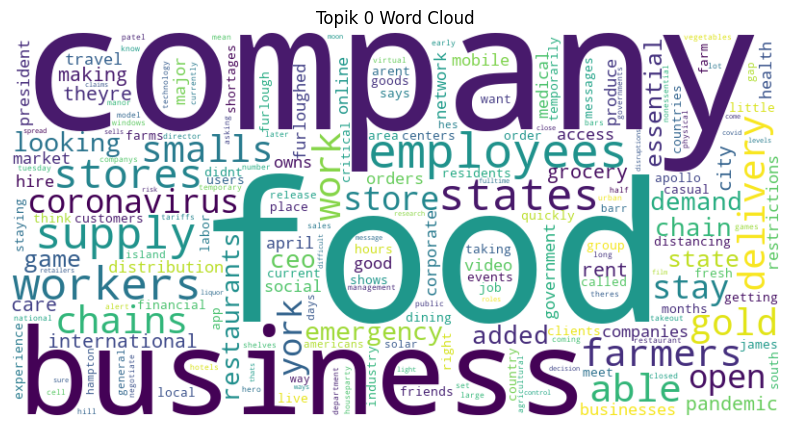


WordCloud Topik 1


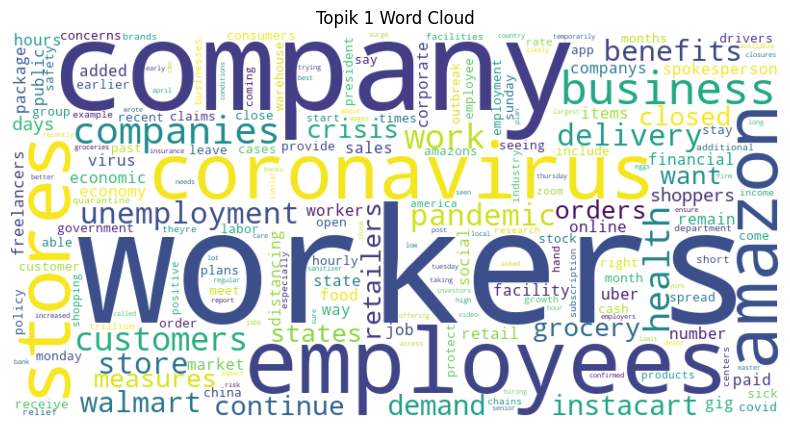


WordCloud Topik 2


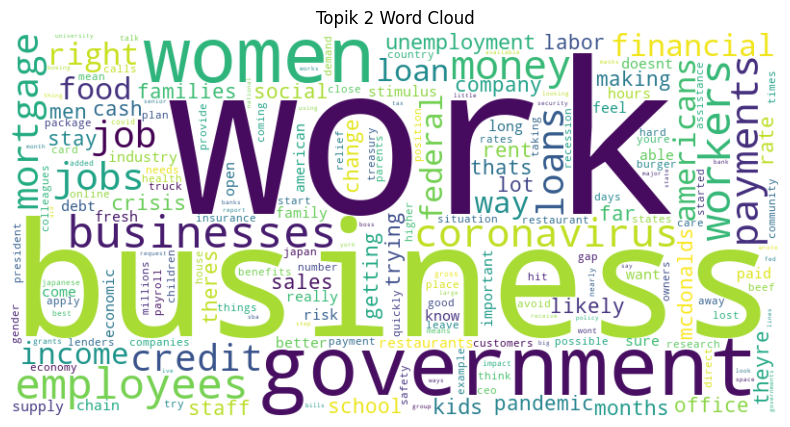


WordCloud Topik 3


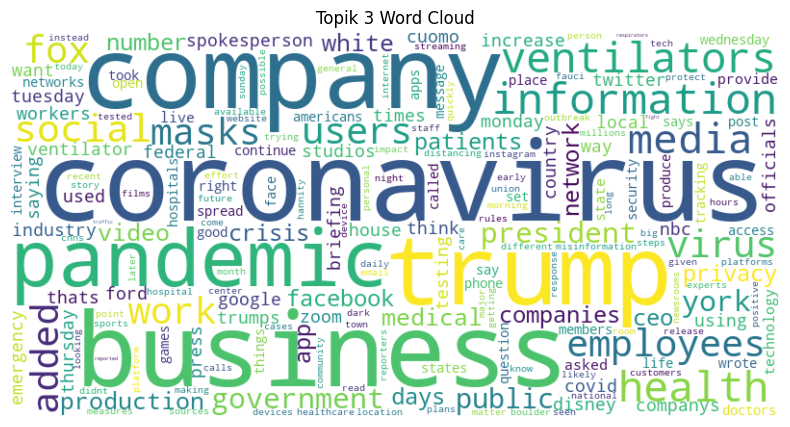


WordCloud Topik 4


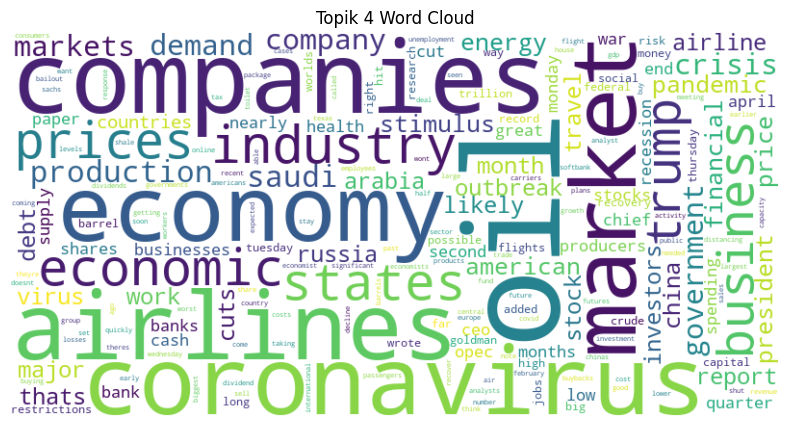

In [33]:
### WORDCLOUD PERTOPIK

for topic_idx, topic in enumerate(lda_model.components_):
    print(f"\nWordCloud Topik {topic_idx}")
    word_freq = {feature_names[i]: topic[i] for i in range(len(feature_names))}
    wc = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(word_freq)
    plt.figure(figsize=(10,5))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(f"Topik {topic_idx} Word Cloud")
    plt.show()

In [34]:
### Tabel Kata Dominan per Topik

top_words = 5
topics_data = []

for topic_idx, topic in enumerate(lda_model.components_):
    top_features_indices = topic.argsort()[:-top_words - 1:-1]
    top_features = [feature_names[i] for i in top_features_indices]
    top_weights = topic[top_features_indices]
    for word, weight in zip(top_features, top_weights):
        topics_data.append({'Topic': f'Topic_{topic_idx}', 'Word': word, 'Weight': weight})

topics_df = pd.DataFrame(topics_data)
print("Tabel Kata Dominan per Topik:")
display(topics_df)

Tabel Kata Dominan per Topik:


,Topic,Word,Weight
0,Topic_0,food,65.315978
1,Topic_0,company,53.309607
2,Topic_0,business,48.339437
3,Topic_0,employees,48.182062
4,Topic_0,workers,43.310099
5,Topic_1,workers,307.839102
6,Topic_1,company,175.467638
7,Topic_1,employees,152.201352
8,Topic_1,coronavirus,136.238942
9,Topic_1,stores,133.071047


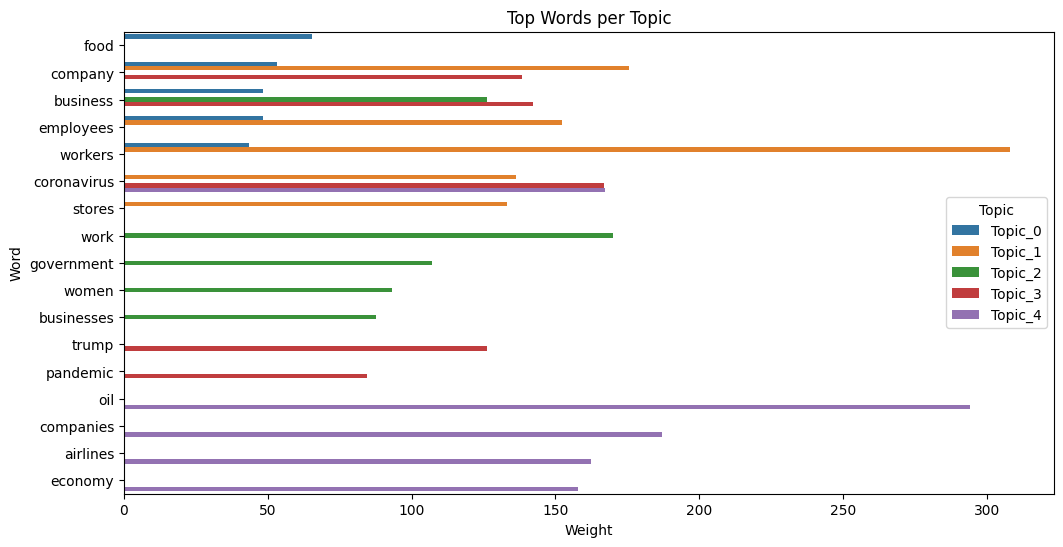

In [35]:
### Bar Chart Kata Dominan per Topik

plt.figure(figsize=(12,6))
sns.barplot(x='Weight', y='Word', hue='Topic', data=topics_df)
plt.title('Top Words per Topic')
plt.xlabel('Weight')
plt.ylabel('Word')
plt.legend(title='Topic')
plt.show()

C:\Users\Java Computer\AppData\Local\Temp\ipykernel_12924\3388282631.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Weight', y='Word', data=df_plot, palette='viridis')


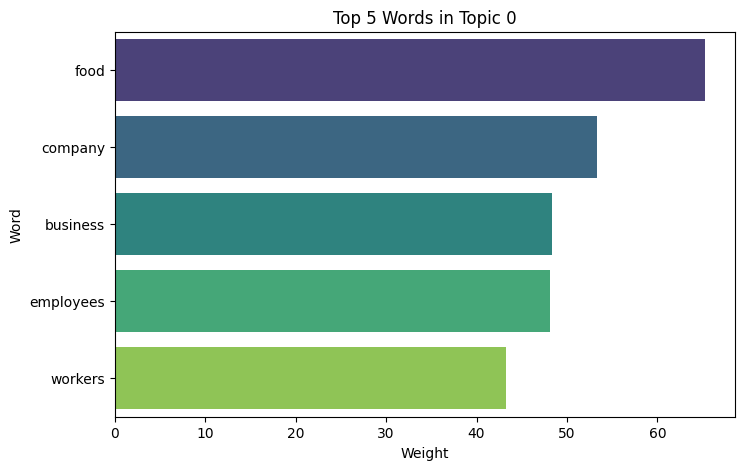

C:\Users\Java Computer\AppData\Local\Temp\ipykernel_12924\3388282631.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Weight', y='Word', data=df_plot, palette='viridis')


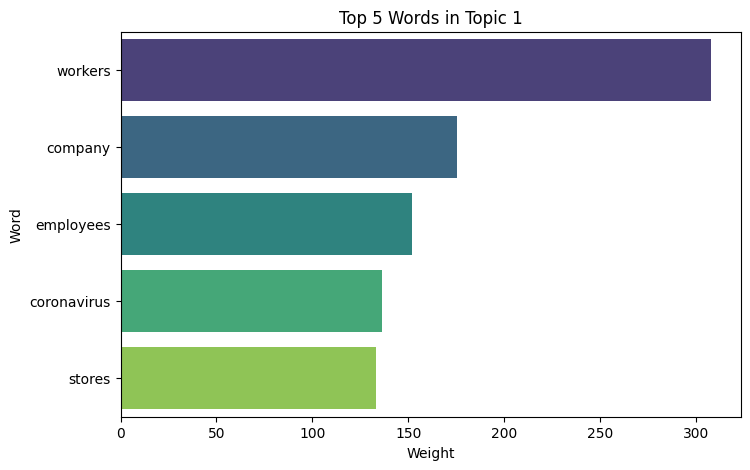

C:\Users\Java Computer\AppData\Local\Temp\ipykernel_12924\3388282631.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Weight', y='Word', data=df_plot, palette='viridis')


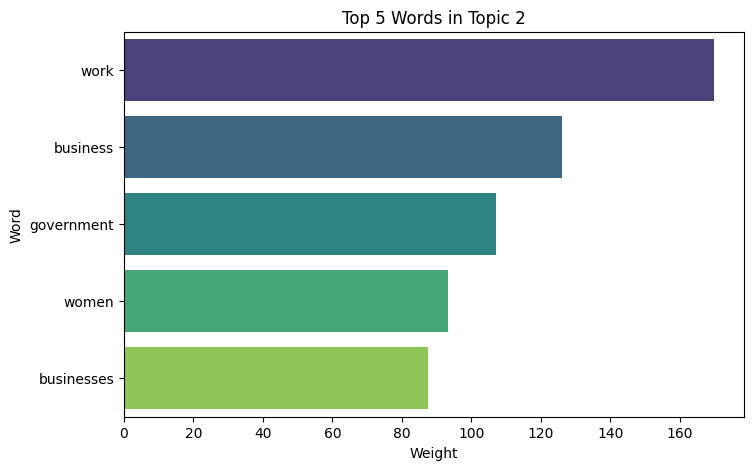

C:\Users\Java Computer\AppData\Local\Temp\ipykernel_12924\3388282631.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Weight', y='Word', data=df_plot, palette='viridis')


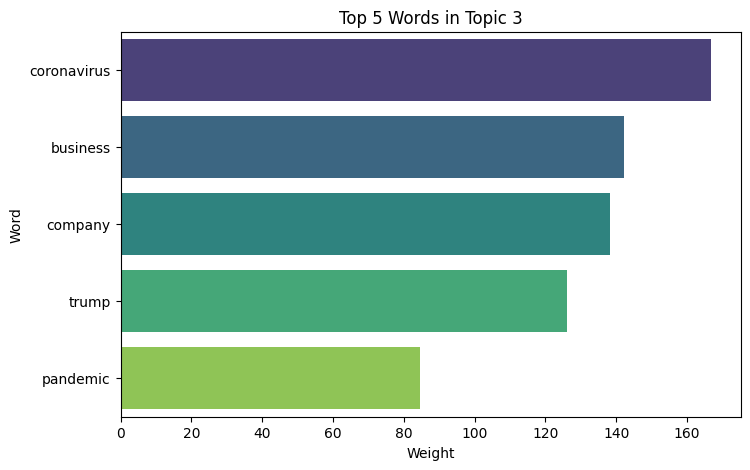

C:\Users\Java Computer\AppData\Local\Temp\ipykernel_12924\3388282631.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Weight', y='Word', data=df_plot, palette='viridis')


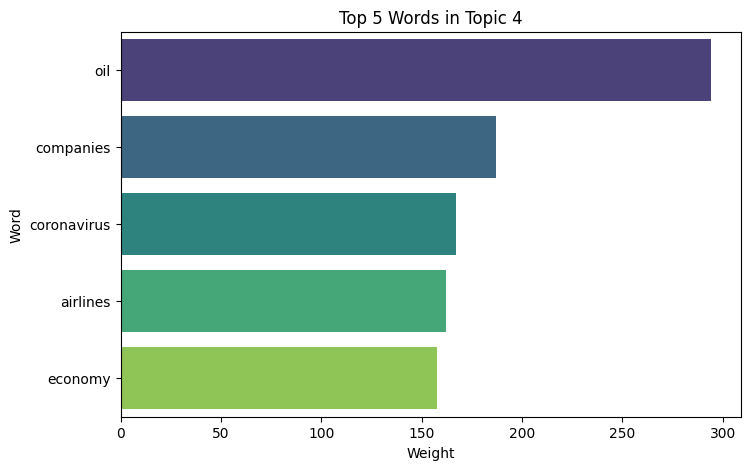

In [36]:
### Bar Chart per Topik
n_topics = lda_model.n_components
for t in range(n_topics):
    plt.figure(figsize=(8,5))
    df_plot = topics_df[topics_df['Topic'] == f'Topic_{t}']
    sns.barplot(x='Weight', y='Word', data=df_plot, palette='viridis')
    plt.title(f'Top {top_words} Words in Topic {t}')
    plt.xlabel('Weight')
    plt.ylabel('Word')
    plt.show()

# Gunakan implementasi menggunakan PCA atau T-sne untuk tahap lanjutan

In [37]:
doc_topics = lda_model.transform(X_count)
dominant_topic = np.argmax(doc_topics, axis=1)

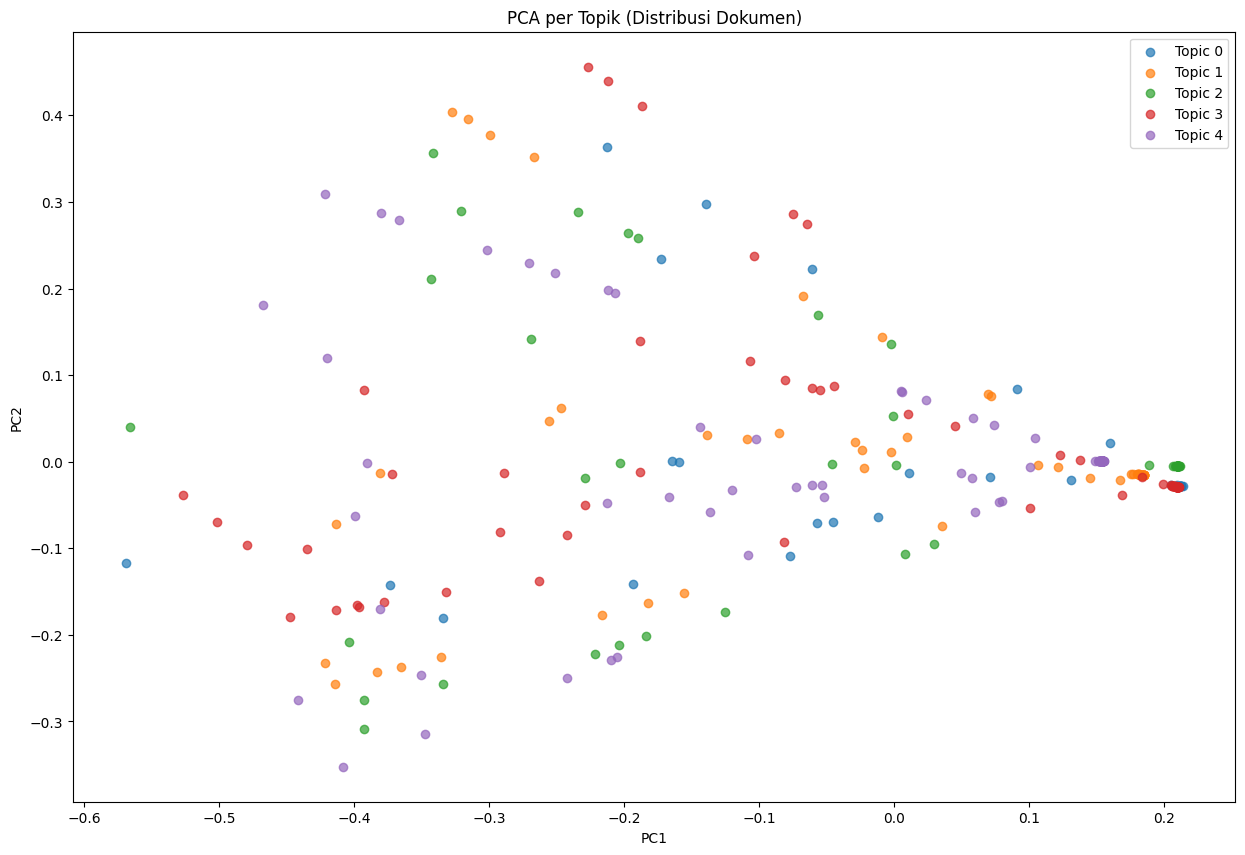

In [38]:
### a. pca

dominant_topic = doc_topics.argmax(axis=1)
n_topics = doc_topics.shape[1]
pca = PCA(n_components=2)

plt.figure(figsize=(15, 10))
for topic_idx in range(n_topics):
    topic_docs = doc_topics[dominant_topic == topic_idx]
    if topic_docs.shape[0] < 2:
        continue
    pca_result = pca.fit_transform(topic_docs)
    plt.scatter(
        pca_result[:, 0],
        pca_result[:, 1],
        label=f"Topic {topic_idx}",
        alpha=0.7
    )
plt.title("PCA per Topik (Distribusi Dokumen)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()


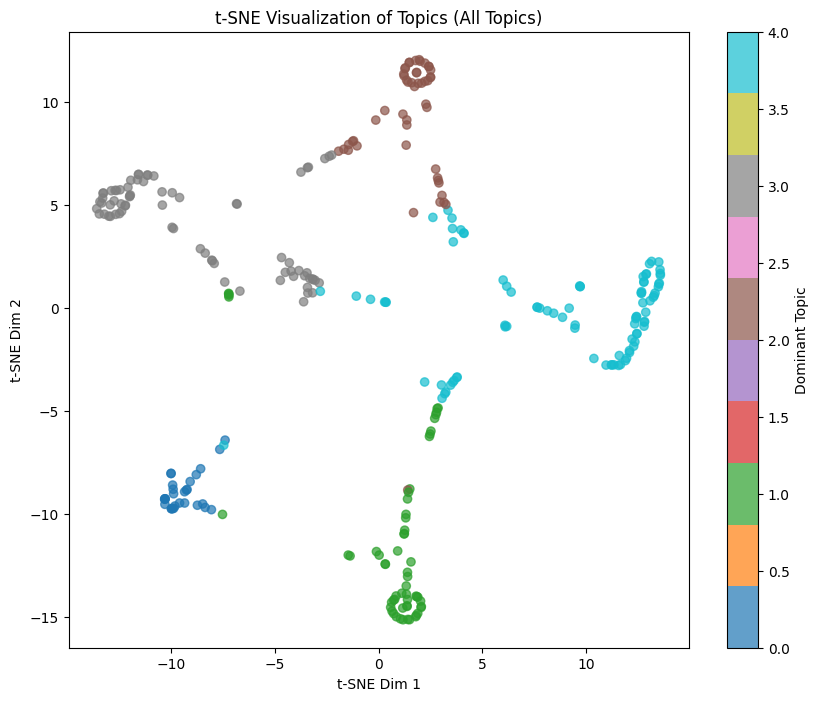

In [39]:
### b. t-sne

dominant_topic = doc_topics.argmax(axis=1)

tsne = TSNE(n_components=2, perplexity=30, random_state=42)
tsne_result = tsne.fit_transform(doc_topics)

plt.figure(figsize=(10,8))
scatter = plt.scatter(
    tsne_result[:,0], tsne_result[:,1],
    c=dominant_topic,
    cmap='tab10',
    alpha=0.7
)
plt.colorbar(scatter, label='Dominant Topic')
plt.title("t-SNE Visualization of Topics (All Topics)")
plt.xlabel("t-SNE Dim 1")
plt.ylabel("t-SNE Dim 2")
plt.show()


Running t-SNE for Topic 0 (n=29, perplexity=14)


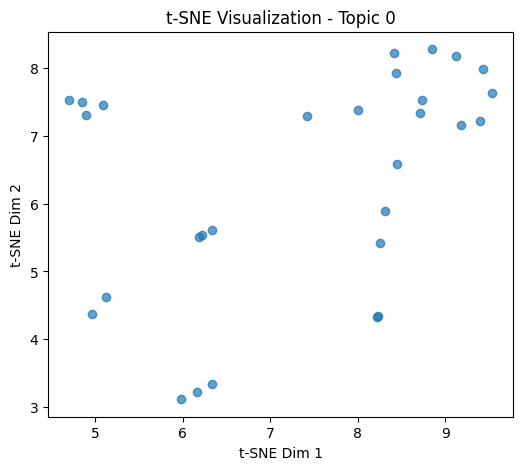

Running t-SNE for Topic 1 (n=59, perplexity=29)


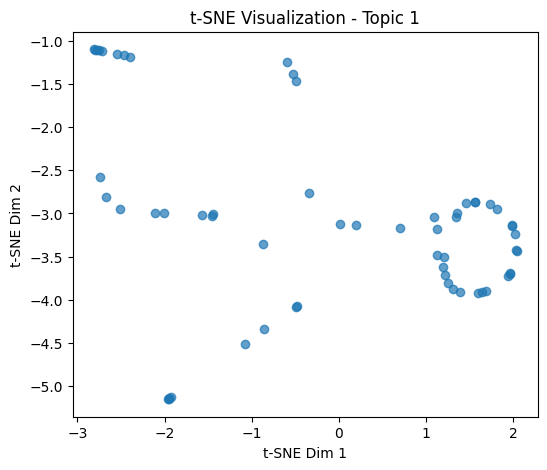

Running t-SNE for Topic 2 (n=50, perplexity=25)


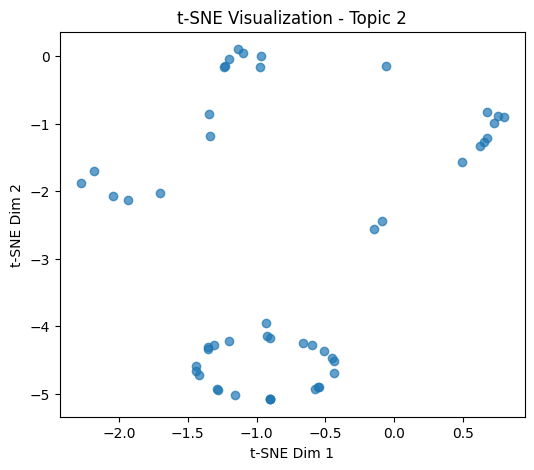

Running t-SNE for Topic 3 (n=73, perplexity=30)


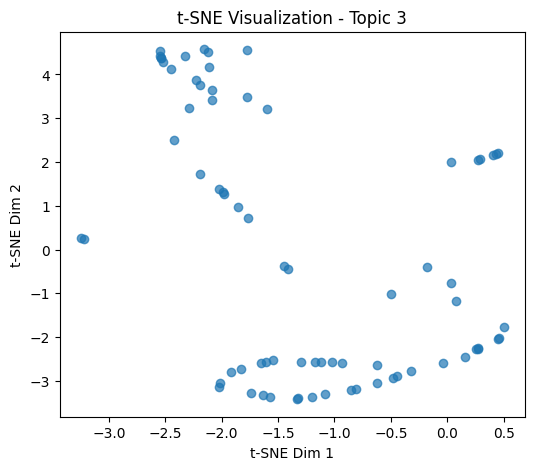

Running t-SNE for Topic 4 (n=90, perplexity=30)


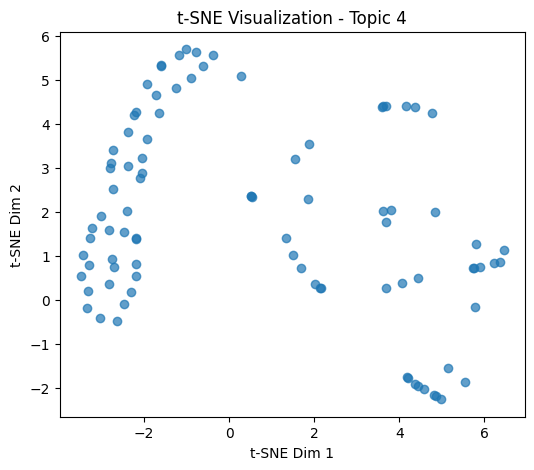

In [40]:
### b. t-sne2
dominant_topic = doc_topics.argmax(axis=1)
n_topics = doc_topics.shape[1]

for topic_idx in range(n_topics):
    topic_docs = doc_topics[dominant_topic == topic_idx]
    n_samples = topic_docs.shape[0]
    if n_samples < 3:
        print(f"Skip Topic {topic_idx}: hanya {n_samples} dokumen.")
        continue
    perplexity = min(30, max(5, n_samples // 2))

    print(f"Running t-SNE for Topic {topic_idx} (n={n_samples}, perplexity={perplexity})")

    tsne = TSNE(n_components=2, perplexity=perplexity, random_state=42)
    tsne_result = tsne.fit_transform(topic_docs)
    plt.figure(figsize=(6,5))
    plt.scatter(tsne_result[:, 0], tsne_result[:, 1], color='tab:blue', alpha=0.7)
    plt.title(f"t-SNE Visualization - Topic {topic_idx}")
    plt.xlabel("t-SNE Dim 1")
    plt.ylabel("t-SNE Dim 2")
    plt.show()
